# PART A
# THEORY

## providing explanation of tensors usnig numpy

In [1]:
# 0D tensor / scaler
import numpy as np
scaler=np.array(10)
print(scaler)
print(scaler.shape)

10
()


In [2]:
# 1D tensor/vector
vector=np.array([1,2,3])
print(vector)
print(vector.shape)

[1 2 3]
(3,)


In [3]:
# 2D tensor/matrix
mat=np.array([[1,2,3],[4,5,6]])
print(mat)
print(mat.shape)

[[1 2 3]
 [4 5 6]]
(2, 3)


In [4]:
# 3D tensor/3D matrix
tensor_3d=np.array([[[1,2],[3,4]],[[5,6],[7,8]]])
print(tensor_3d)
print(tensor_3d.shape)


[[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]
(2, 2, 2)


# PART B
# data acquisition

## 1) usnig CSV

In [79]:
import pandas as pd
df_csv=pd.read_csv(r'C:\Users\Ahmed\OneDrive\Desktop\all projects\data preprocessing and feature engineering\project-1\customer_churn_200.csv', 
sep=',',
index_col=False,
encoding='utf-8',
header=0
)

In [20]:
df_csv.sample(5)

,CustomerID,Age,Gender,Income,Purchases,TotalSpent,Visits,SupportCalls,City,TenureMonths,Churn
11,C012,41.0,Male,36711.0,10,29163.75,6,2,Bengaluru,18,Yes
112,C113,58.0,Male,50217.0,4,10526.49,9,3,Mumbai,13,Yes
194,C195,61.0,Male,22000.0,2,1637.96,9,4,Ahmedabad,54,Yes
185,C186,20.0,Male,106223.0,5,10492.23,5,1,Surat,38,Yes
58,C059,34.0,Female,95575.0,4,5991.06,3,2,Hyderabad,39,No


## 2) using json

In [40]:
df=pd.read_json(r'C:\Users\Ahmed\OneDrive\Desktop\all projects\data preprocessing and feature engineering\project-1\customer_churn_200.json',

)

In [8]:
df.sample(5)

,CustomerID,Age,Gender,Income,Purchases,TotalSpent,Visits,SupportCalls,City,TenureMonths,Churn
10,C011,28.0,Female,51828.0,7,23409.76,7,1,Mumbai,19,Yes
69,C070,61.0,Female,117157.0,9,13744.75,10,3,Pune,9,No
4,C005,NaN,Male,100989.0,8,7168.33,11,0,Surat,3,No
11,C012,41.0,Male,36711.0,10,29163.75,6,2,Bengaluru,18,Yes
152,C153,47.0,Male,78403.0,12,13565.01,11,3,Surat,58,Yes


## 3) using SQl

In [41]:
import mysql.connector
conn=mysql.connector.connect(host='localhost',user='root',password='',database='customer_churn')
df=pd.read_sql_query('select * from  customer_data',conn)
df.sample(5)

C:\Users\Ahmed\AppData\Local\Temp\ipykernel_24856\1649965294.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql_query('select * from  customer_data',conn)


,CustomerID,Age,Gender,Income,Purchases,TotalSpent,Visits,SupportCalls,City,TenureMonths,Churn
105,C106,25.0,Male,104672.0,4,8860.92,11,3,Delhi,9,Yes
181,C182,18.0,Male,48977.0,9,27921.29,12,1,Pune,55,No
21,C022,55.0,None,24102.0,2,5825.42,8,2,Ahmedabad,49,No
137,C138,22.0,Female,103067.0,4,3770.28,6,0,Bengaluru,51,No
63,C064,23.0,Male,105922.0,9,25381.06,10,1,Pune,57,No


## 4) using API (random user api)

In [42]:
import requests
response=requests.get('https://products-u9g7r5h5qn.mock.tool.postman.dev/products')
df=pd.DataFrame(response.json()['data'])
df.sample(5)

,Age,Churn,City,CustomerID,Gender,Income,Purchases,SupportCalls,TenureMonths,TotalSpent,Visits,id
23,39,Yes,Delhi,1024,Female,65000,2,8,6,7000,4,24
22,33,No,Ahmedabad,1023,Male,50000,6,3,15,18000,10,23
10,40,Yes,Mumbai,1011,Male,68000,3,7,7,8500,5,11
30,42,Yes,Mumbai,1031,Male,70000,4,5,10,12000,6,31
38,36,Yes,Delhi,1039,Male,56000,3,7,8,9000,5,39


# PART C
# DATA UNDERSTANDING AND CLEANING

### initial exploration (working on csv file)


In [21]:
df_csv

,CustomerID,Age,Gender,Income,Purchases,TotalSpent,Visits,SupportCalls,City,TenureMonths,Churn
0,C001,56.0,Male,91744.0,5,14073.80,3,1,Mumbai,11,No
1,C002,46.0,Female,74491.0,7,18055.77,7,4,Ahmedabad,14,No
2,C003,32.0,Male,36589.0,6,17794.52,6,1,Bengaluru,2,No
3,C004,60.0,Female,61484.0,6,6506.95,6,3,Surat,40,No
4,C005,NaN,Male,100989.0,8,7168.33,11,0,Surat,3,No
...,...,...,...,...,...,...,...,...,...,...,...
195,C196,41.0,Female,88588.0,5,4773.28,4,1,Surat,40,No
196,C197,NaN,Male,119042.0,9,12672.94,13,0,Pune,51,No
197,C198,49.0,Female,111610.0,7,8082.50,5,3,Bengaluru,8,Yes
198,C199,49.0,Male,115856.0,8,15014.86,5,1,Bengaluru,18,Yes


In [ ]:
# initial 5 entries
df_csv.head()

,CustomerID,Age,Gender,Income,Purchases,TotalSpent,Visits,SupportCalls,City,TenureMonths,Churn
0,C001,56.0,Male,91744.0,5,14073.80,3,1,Mumbai,11,No
1,C002,46.0,Female,74491.0,7,18055.77,7,4,Ahmedabad,14,No
2,C003,32.0,Male,36589.0,6,17794.52,6,1,Bengaluru,2,No
3,C004,60.0,Female,61484.0,6,6506.95,6,3,Surat,40,No
4,C005,NaN,Male,100989.0,8,7168.33,11,0,Surat,3,No


In [43]:
# data information
df_csv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   CustomerID    200 non-null    object 
 1   Age           194 non-null    float64
 2   Gender        197 non-null    object 
 3   Income        195 non-null    float64
 4   Purchases     200 non-null    int64  
 5   TotalSpent    200 non-null    float64
 6   Visits        200 non-null    int64  
 7   SupportCalls  200 non-null    int64  
 8   City          200 non-null    object 
 9   TenureMonths  200 non-null    int64  
 10  Churn         200 non-null    object 
dtypes: float64(3), int64(4), object(4)
memory usage: 17.3+ KB


In [44]:
# descriptive statistics
df_csv.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,194.0,42.139175,13.842048,18.00,31.0000,43.000,54.0000,65.00
Income,195.0,70696.353846,30163.807910,18301.00,45154.5000,72340.000,96719.0000,119279.00
Purchases,200.0,6.145000,2.574317,1.00,4.0000,6.000,8.0000,12.00
TotalSpent,200.0,13229.153800,7492.797145,1086.01,7748.1025,12493.415,17278.2625,41727.46
Visits,200.0,8.140000,2.860298,2.00,6.0000,8.000,10.0000,16.00
SupportCalls,200.0,1.850000,1.369994,0.00,1.0000,2.000,3.0000,6.00
TenureMonths,200.0,30.325000,17.366559,1.00,16.0000,30.000,45.0000,60.00


In [76]:
# identifying null values
df_csv.isnull().sum()

CustomerID      0
Age             0
Gender          3
Income          5
Purchases       0
TotalSpent      0
Visits          0
SupportCalls    0
City            0
TenureMonths    0
Churn           0
dtype: int64

In [29]:
# identifying duplicates
df_csv.duplicated().sum()

np.int64(0)

In [45]:
# size of dataset
df_csv.shape

(200, 11)

### data cleaning

In [80]:
# removing duplicates (there are no duplicates just for learning purpose ...)
df_csv.drop_duplicates(inplace=True)


In [81]:
# handling datatypes
df_csv.dtypes

CustomerID       object
Age             float64
Gender           object
Income          float64
Purchases         int64
TotalSpent      float64
Visits            int64
SupportCalls      int64
City             object
TenureMonths      int64
Churn            object
dtype: object

In [85]:

df_csv["Age"] = df_csv["Age"].astype(int)

In [134]:
# handling missing values
df_csv.isnull().sum()

CustomerID      0
Age             0
Gender          0
Income          0
Purchases       0
TotalSpent      0
Visits          0
SupportCalls    0
City            0
TenureMonths    0
Churn           0
dtype: int64

In [82]:
# filling age
df_csv["Age"] = df_csv["Age"].fillna(df_csv["Age"].mean())
df_csv

,CustomerID,Age,Gender,Income,Purchases,TotalSpent,Visits,SupportCalls,City,TenureMonths,Churn
0,C001,56.000000,Male,91744.0,5,14073.80,3,1,Mumbai,11,No
1,C002,46.000000,Female,74491.0,7,18055.77,7,4,Ahmedabad,14,No
2,C003,32.000000,Male,36589.0,6,17794.52,6,1,Bengaluru,2,No
3,C004,60.000000,Female,61484.0,6,6506.95,6,3,Surat,40,No
4,C005,42.139175,Male,100989.0,8,7168.33,11,0,Surat,3,No
...,...,...,...,...,...,...,...,...,...,...,...
195,C196,41.000000,Female,88588.0,5,4773.28,4,1,Surat,40,No
196,C197,42.139175,Male,119042.0,9,12672.94,13,0,Pune,51,No
197,C198,49.000000,Female,111610.0,7,8082.50,5,3,Bengaluru,8,Yes
198,C199,49.000000,Male,115856.0,8,15014.86,5,1,Bengaluru,18,Yes


In [140]:
# filling gender
df_csv['Gender']=df_csv['Gender'].fillna(df_csv['Gender'].mode()[0])
df_csv["Gender"] = df_csv["Gender"].str.strip()
df_csv["Gender"] = df_csv["Gender"].str.capitalize()

In [84]:
# filling income
df_csv['Income'] = df_csv['Income'].fillna(df_csv['Income'].mean())

# PART D EXPLORATORY DATA ANALYSIS

### Univariate analysis

Text(0.5, 1.0, 'Purchases Distribution')

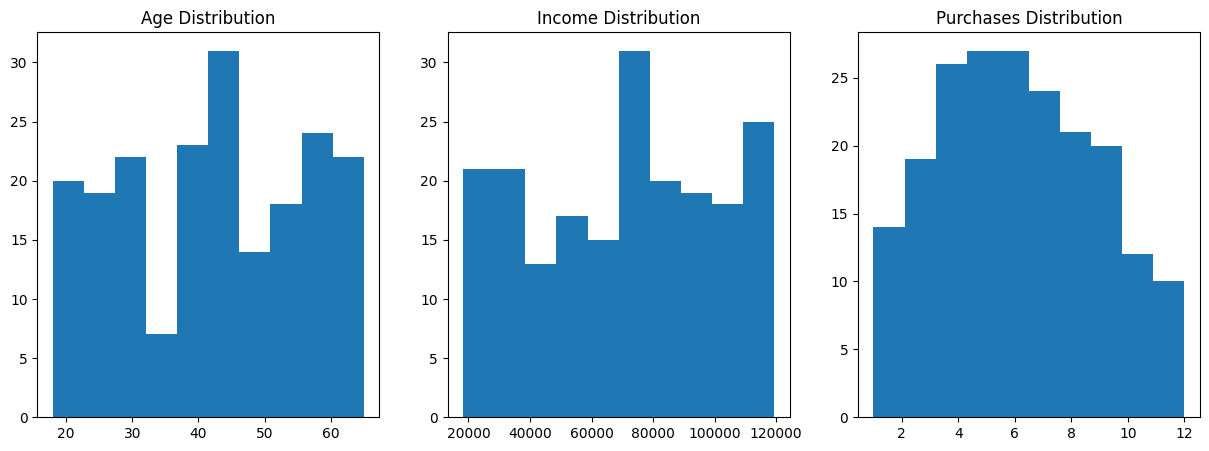

In [125]:
# numerical variable (age,income,purchases)
# histogram
import matplotlib.pyplot as plt
import seaborn as sns
fig,axes=plt.subplots(1,3,figsize=(15,5))
axes[0].hist(df_csv['Age'],bins=10)
axes[0].set_title('Age Distribution')
axes[1].hist(df_csv['Income'],bins=10)
axes[1].set_title('Income Distribution')
axes[2].hist(df_csv['Purchases'],bins=10)
axes[2].set_title('Purchases Distribution')

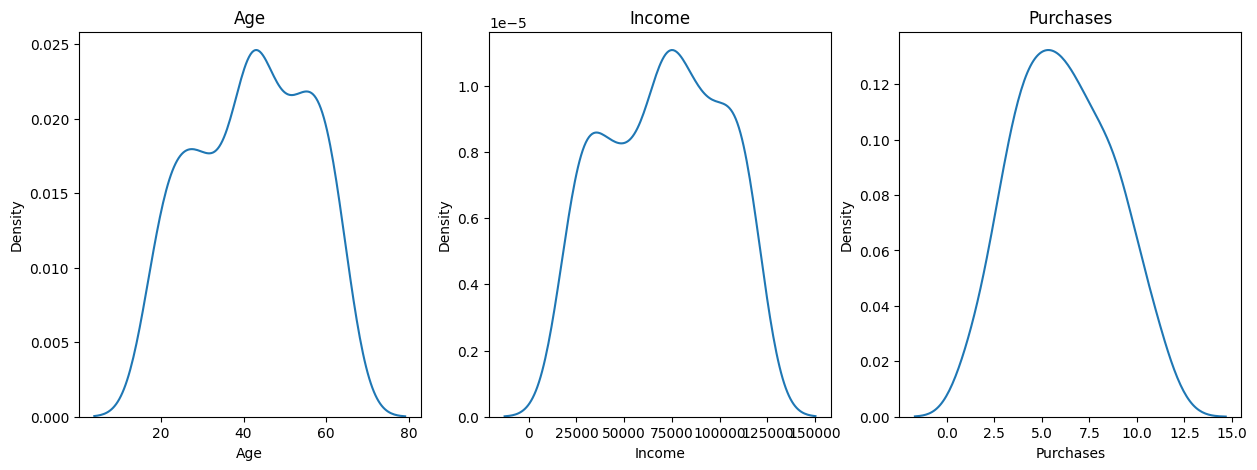

In [133]:
# distplot
fig,axes=plt.subplots(1,3,figsize=(15,5))
sns.kdeplot(df_csv["Age"], ax=axes[0])
sns.kdeplot(df_csv["Income"], ax=axes[1])
sns.kdeplot(df_csv["Purchases"],  ax=axes[2])
axes[0].set_title("Age")
axes[1].set_title("Income")
axes[2].set_title("Purchases")

plt.show()

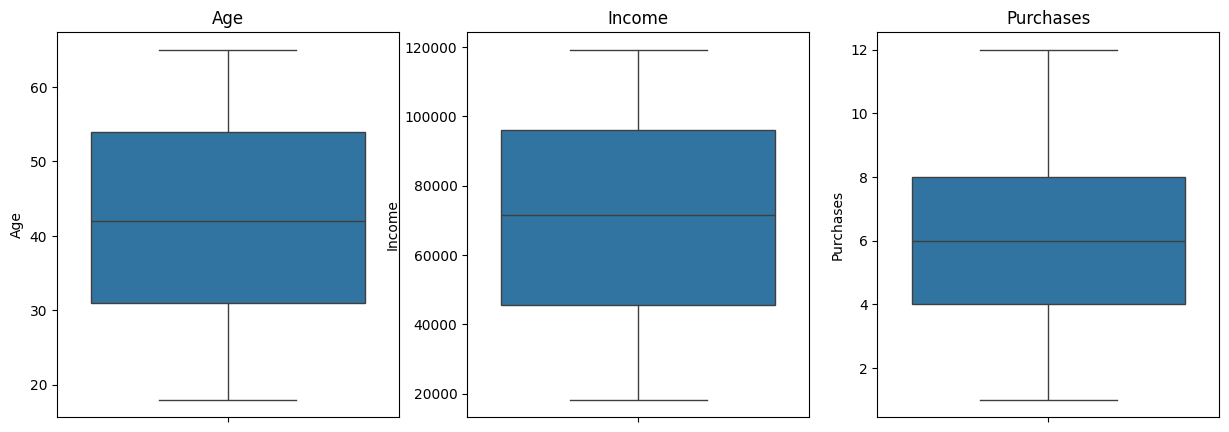

In [137]:
# boxplot
fig,axes=plt.subplots(1,3,figsize=(15,5))
sns.boxplot(df_csv["Age"], ax=axes[0])
sns.boxplot(df_csv["Income"], ax=axes[1])
sns.boxplot(df_csv["Purchases"],  ax=axes[2])
axes[0].set_title("Age")
axes[1].set_title("Income")
axes[2].set_title("Purchases")
plt.show()

### bivariate analysis

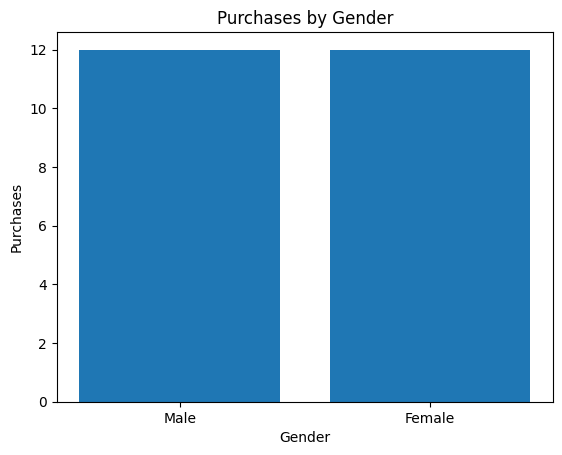

In [142]:
# categorical vs numerical (gender,purchases)
plt.bar(df_csv['Gender'], df_csv['Purchases'])
plt.title('Purchases by Gender')
plt.xlabel('Gender')
plt.ylabel('Purchases')
plt.show()


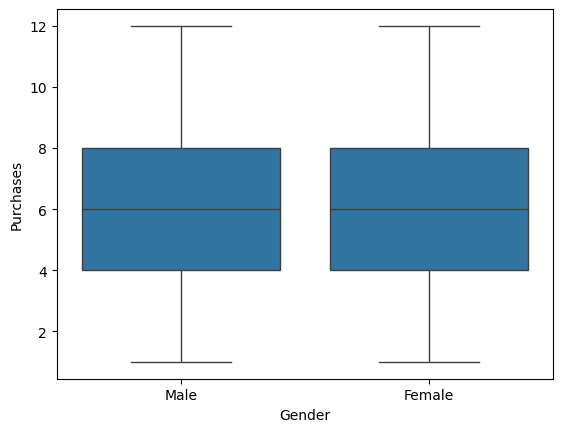

In [144]:
# box plot (gender vs purchases)
sns.boxplot(x='Gender', y='Purchases', data=df_csv)
plt.show()




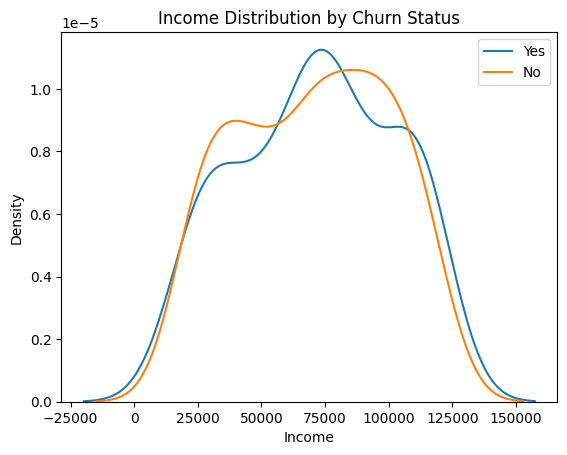

In [152]:
# bar plot (income vs churn)
sns.kdeplot(df_csv[df_csv['Churn']=='Yes']['Income'], label='Yes')
sns.kdeplot(df_csv[df_csv['Churn']=='No']['Income'], label='No')
plt.legend()
plt.xlabel('Income')
plt.ylabel('Density')
plt.title('Income Distribution by Churn Status')
plt.show()

### MULTIVARIATE ANALYSIS

<Axes: >

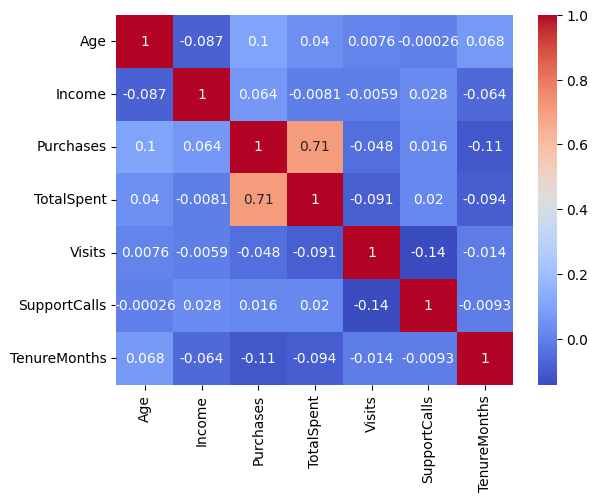

In [ ]:
# correlation heatmap of all numerical varibale 
sns.heatmap(df_csv.corr(numeric_only=True),annot=True,cmap='coolwarm')

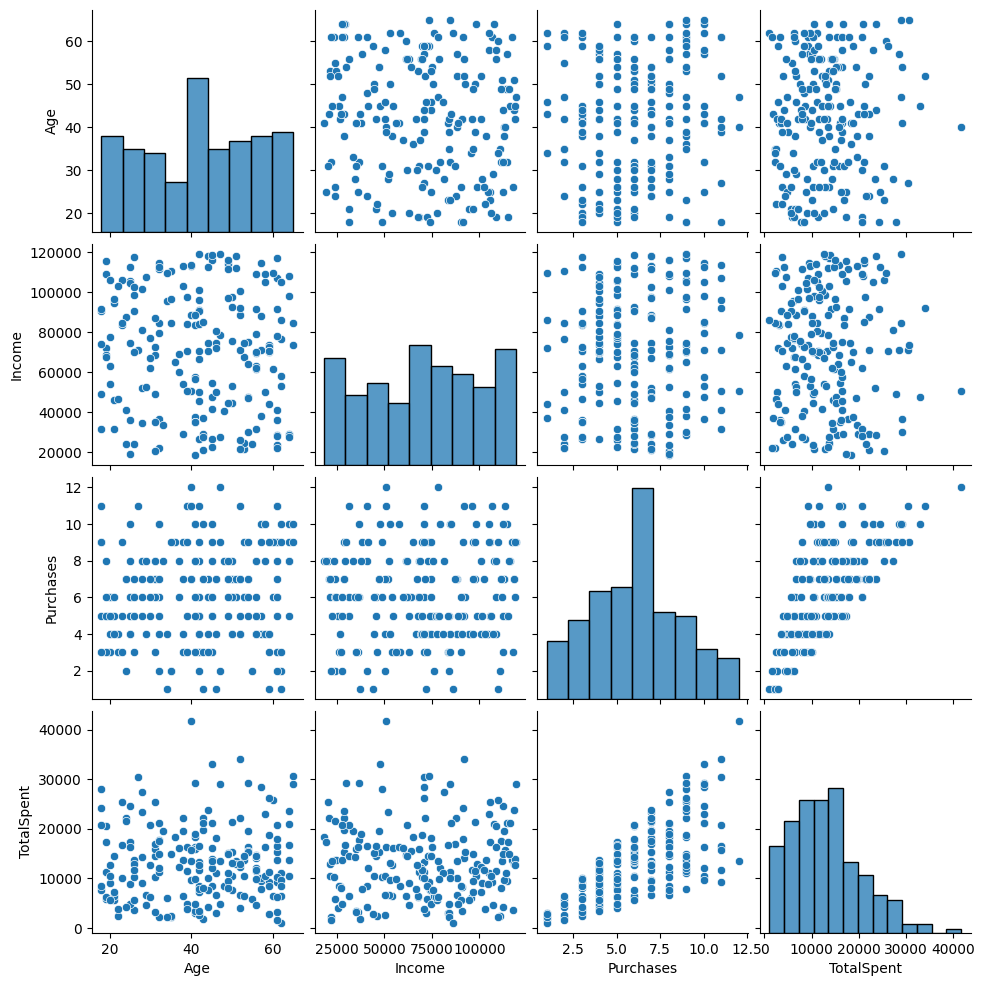

In [ ]:
# pairplot to identify feature interactions
sns.pairplot(df_csv,vars=['Age', 'Income', 'Purchases','TotalSpent'])

# PART E DATA PROFILING

### pandas profiling using ydata-profiling

In [166]:
from ydata_profiling import ProfileReport
profile=ProfileReport(df_csv)
profile.to_file(output_file='ProfileReport.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 11/11 [00:00<00:00, 66.29it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]